# Navigation: the infinite plane and the cylinder

*Section "Navigation scenarios: infinite plane and cylinder" of the paper.*

An observer moves through a textured world. In this notebook the **target** is the focus of expansion (FoE)
of the optic flow, that is the direction of the egomotion, and it moves **slowly**: the heading $h(t)$ of the
observer diffuses around a mean $\bar h$. Two tasks probe the ability of a model to find it.

* **Infinite plane** (benchmark **AVB1**, `plane`). The observer estimates the direction of its egomotion, as accurately as possible. The
  model returns an estimate $\hat h$ of the heading at each step, and the score is the **estimation error**
  $e = |\hat h - h|$ (the root-mean-square and the median over the trials).
* **Cylinder** (benchmark **AVB2**, `cylinder`). The observer moves along the axis of a tunnel, and a model must keep its **gaze on the axis**,
  that is bring the FoE back to the centre of the image, by rotating the gaze.

## Contents

1. [The model](#The-model)
2. [The infinite plane](#The-infinite-plane), with [a harder problem: noise in the images](#A-harder-problem:-noise-in-the-images)
3. [A passive example: the true and the estimated heading](#A-passive-example:-the-true-and-the-estimated-heading)
4. [The cylinder: keep the gaze on the axis](#The-cylinder:-keep-the-gaze-on-the-axis), with [the observer moves where it looks](#The-observer-moves-where-it-looks)
5. [Checks](#Checks)


## The model

**Slow diffusion of the target.** The heading is $h(t) = \bar h + x(t)$ where $x$ is a slow Langevin diffusion
of time constant $\tau$ and stationary amplitude $\sigma_\mathrm{OU}$: a hidden drive $y$ relaxes under a
white random force $w$ and is integrated by the damped signal $x$,

$$\tau\,\dot y = -y + w(t), \qquad \tau\,\dot x = y - x .$$

It is smooth, and its autocorrelation is $(1 + |\Delta t|/\tau)\,e^{-|\Delta t|/\tau}$.

**Plane.** A trial is a *target present* trial if the heading is decentred from the gaze by $|\bar h| \geq 2\,\delta_\mathrm{min}$
(a *target absent* trial has $\bar h = 0$). The decision of a model is "decentred" if $|\hat h - g| > \delta_\mathrm{min}$.
With the hits ($N_+$ target-present trials) and the false alarms ($N_-$ target-absent trials) the metrics of
the paper are

$$A = \frac{\text{hits} + \text{correct rejections}}{N}, \quad
  H = \frac{\text{hits}}{N_+}, \quad F = \frac{\text{false alarms}}{N_-}, \quad d' = z(H) - z(F),$$

with the loglinear correction of Hautus (1995) (0.5 is added to the counts and 1 to the number of trials) so
that $d'$ is finite when a rate is 0 or 1.

**Cylinder.** With the gaze $g$, the FoE is at $e = h - g$ in the image. A model that returns the rotation
$\Delta g_k = \kappa\,\hat e_k$ (the gain $\kappa$ and the estimate $\hat e$ of the FoE) obeys

$$e_{k+1} = e_k + \Delta h_k - \kappa\,\hat e_k ,$$

where $\Delta h_k$ is the exogenous change of the heading. The score is the root-mean-square of $e$.

| Symbol | Name in the code | Default value | Role |
|--------|------------------|---------------|------|
| $\tau$ | `Perturbation.tau` | 1 s | time constant of the diffusion |
| $\sigma_\mathrm{OU}$ | `Perturbation.sigma_ou` | 1 deg (plane), 2 deg (cylinder) | stationary amplitude of the diffusion |
| $h_\mathrm{max}$ | `h_max` | 10 deg | largest mean offset $|\bar h|$ of a trial |
| $\delta_\mathrm{min}$ | `delta_min` | 2 deg | offset of a *target present* trial, and decision threshold |
| | `present_fraction` | 0.5 | fraction of the target-present trials |
| | `n_steps` | 30 (plane), 300 (cylinder) | number of steps of a trial |
| | `noise_std` | 0 | standard deviation of the noise added to the images (luminance 0-1) |
| | `speed` | 4 m/s (plane), 6 m/s (cylinder) | speed of the camera |
| $\kappa$ | `gain` | 0.4 | fraction of the estimated FoE offset that is corrected at each step |
| | `alpha` | 1 | weight of a new estimate in the smoothing of the model (1: no smoothing) |
| | `yaw_range` | 0 deg/frame (plane), 0.2 deg/frame (cylinder) | range of the yaw rotation fitted jointly with the FoE |
| | `heading_lag` | `None` | time constant with which the heading follows the gaze (see below) |

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().parent          # the repository, when the package is not installed
sys.path.insert(0, str(ROOT))

import numpy as np

import ActiveVisionBenchmark as avb
from functools import partial

cached = partial(avb.cached, cache_dir=ROOT / "cache")
save = partial(avb.save_figure, directory=ROOT / "figures")

# Colour-blind safe palette (Okabe-Ito)
BLUE, ORANGE, GREY = "#0072B2", "#E69F00", "#666666"

import os

N_JOBS = os.cpu_count()
SEED = 42

## The infinite plane

The code below is **Listing 1 of the paper**. A Motion Clouds texture is projected onto a ground plane and the
bundled models are evaluated on a dataset of 200 trials: a random estimate, which is the chance baseline, and
`FlowHeadingModel`, which estimates the FoE directly from the brightness of two successive frames.

### Benchmark AVB1: `plane`

The observer looks at the horizon of an infinite ground plane and **estimates the direction of its egomotion**:
the target is the FoE, which diffuses slowly around a mean offset. The model returns an estimate $\hat h$ of the
heading at every step. This benchmark is **passive**: the actions of the models do not move the camera.

| Symbol | Name in the code | Value | Role |
|--------|------------------|-------|------|
| $\delta_\mathrm{min}$ | `delta_min` | 2 deg | decentring above which a trial is *target present*, and decision threshold of the models |
| $h_\mathrm{max}$ | `h_max` | 10 deg | largest mean offset of the heading in a trial |
| | `present_fraction` | 0.5 | fraction of the *target present* trials |
| | `camera_height` | 1.5 m | height of the camera above the plane |
| | `pitch` | 0 deg | elevation of the optical axis |
| | `visual_angle` | 45 deg | visual angle of the width of the image |
| | `size` | 128 pixels | side of the image (from a 256 x 256 texture, the Motion Cloud of the listing) |
| $v$ | `speed` | 4 m/s | speed of the camera |
| $\Delta t$ | `dt` | 1/60 s | duration of a step |
| | `n_steps`, `warmup` | 30, 2 | steps of a trial, and steps ignored by the metrics |
| $\tau$, $\sigma_\mathrm{OU}$ | `perturbation.tau`, `perturbation.sigma_ou` | 1 s, 1 deg | slow diffusion of the heading |
| | `noise_std` | 0 | noise of the images (luminance) |

**Dataset:** 200 trials, seed 42. **Reference models:** `random` (chance level) and `flow` (`FlowHeadingModel`).
**Metrics:** RMS and median estimation error (deg), accuracy $A$, hit rate $H$, false alarm rate $F$ and $d'$.
The cell after the listing prints the values that the task actually uses.


In [2]:
from ActiveVisionBenchmark import Benchmark, HorizontalPlaneTask

# Generate a Motion Clouds texture (the package is optional: a built-in generator is the fallback)
try:
    import MotionClouds as mc
    fx, fy, ft = mc.get_grids(256, 256, 1)
    env = mc.envelope_gabor(fx, fy, ft, B_theta=np.inf)
    image = mc.random_cloud(env, seed=42)
    image = mc.rectif(image)
except ImportError:
    image = avb.MotionCloudStimulus(backend="builtin")((256, 256), seed=42)

# Initialise the task and benchmark
task = HorizontalPlaneTask(image, seed=42)
bench = Benchmark(task)

# Generate a dataset of 200 trials
N_TRIALS = avb.scaled(200, 8)
trials = bench.generate_dataset(n_trials=N_TRIALS)

# Run the benchmark (the result is cached) and print results
results = cached("02_listing1", dict(n_trials=N_TRIALS, stimulus=task.stimulus, seed=42),
                 lambda: bench.evaluate(trials))
for name, res in results.items():
    print(f"{name}: {res.summary()}")

random: Model            : random
Trials           : 200
RMS error (deg)  : 7.625
Median error (deg): 5.809
Accuracy         : 0.545
Hit rate         : 0.850
False alarm rate : 0.760
d'               : 0.324
Mean time (s)    : 0.0193
flow: Model            : flow
Trials           : 200
RMS error (deg)  : 0.552
Median error (deg): 0.448
Accuracy         : 0.970
Hit rate         : 1.000
False alarm rate : 0.060
d'               : 4.098
Mean time (s)    : 0.2989


In [3]:
for name in ("size", "visual_angle", "camera_height", "pitch", "speed", "dt", "n_steps", "warmup", "delta_min", "h_max",
             "present_fraction", "noise_std"):
    print(f"{name:17s} {getattr(task, name)}")
print(f"{'perturbation':17s} {task.perturbation}")
print(f"{'trials, seed':17s} {N_TRIALS}, 42")

size              (128, 128)
visual_angle      45.0
camera_height     1.5
pitch             0.0
speed             4.0
dt                0.016666666666666666
n_steps           30
warmup            2
delta_min         2.0
h_max             10.0
present_fraction  0.5
noise_std         0.0
perturbation      Perturbation(dt=0.016666666666666666, tau=1.0, sigma_ou=1.0, mean=0.0, hazard_rate=0.0, sigma_jump=0.0, limit=None, seed=None, jump_tau=None)
trials, seed      200, 42


The metrics of Table 1 of the paper, and the error of the estimate:

In [4]:
from IPython.display import Markdown

def table(results):
    rows = ["| model | accuracy $A$ | hit rate $H$ | false alarm rate $F$ | $d'$ | RMS error (deg) | median error (deg) |",
            "|---|---|---|---|---|---|---|"]
    for name, r in results.items():
        rows.append(f"| {name} | {r.accuracy:.3f} | {r.hit_rate():.3f} | {r.false_alarm_rate():.3f} | "
                    f"{r.d_prime():.2f} | {r.rms_error:.2f} | {r.median_error:.2f} |")
    return Markdown("\n".join(rows))

table(results)

| model | accuracy $A$ | hit rate $H$ | false alarm rate $F$ | $d'$ | RMS error (deg) | median error (deg) |
|---|---|---|---|---|---|---|
| random | 0.545 | 0.850 | 0.760 | 0.32 | 7.63 | 5.81 |
| flow | 0.970 | 1.000 | 0.060 | 4.10 | 0.55 | 0.45 |

[]

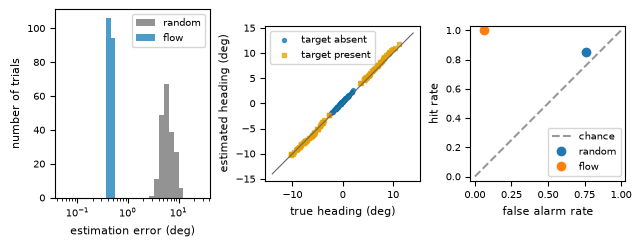

In [5]:
colors = {"random": GREY, "flow": BLUE}
fig, axes = avb.new_figure(16, 6, 1, 3)

bins = np.geomspace(0.05, 30, 30)
for name, res in results.items():
    axes[0].hist([r.error for r in res.trial_results], bins=bins, alpha=0.7, color=colors[name], label=name)
axes[0].set_xscale("log")
axes[0].set_xlabel("estimation error (deg)")
axes[0].set_ylabel("number of trials")
axes[0].legend()

for present, marker in ((False, "o"), (True, "s")):
    chosen = [r for r in results["flow"].trial_results if r.trial.target_present == present]
    axes[1].scatter([r.truth[-1] for r in chosen], [r.estimates[-1] for r in chosen], s=8, marker=marker,
                    color=ORANGE if present else BLUE, alpha=0.7, label="target present" if present else "target absent")
axes[1].plot([-14, 14], [-14, 14], color=GREY, lw=0.8)
axes[1].set_xlabel("true heading (deg)")
axes[1].set_ylabel("estimated heading (deg)")
axes[1].set_aspect("equal")
axes[1].legend()

avb.plot_roc(results, axes[2])
save(fig, "02_plane")

### A harder problem: noise in the images

The images of the models can be corrupted by Gaussian noise (`noise_std`, in units of luminance, between 0 and 1).
The estimation of the FoE is direct and uses all the pixels, so it resists the noise, up to a point. The
chance level does not depend on the noise.

[]

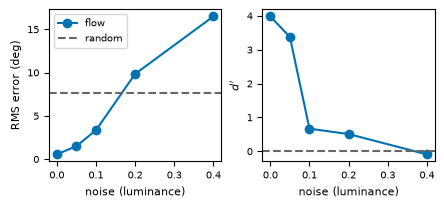

In [6]:
NOISE = [0.0, 0.05, 0.1, 0.2, 0.4]
N_NOISE = avb.scaled(100, 8)

def noise_sweep():
    out = {}
    for sigma in NOISE:
        noisy = HorizontalPlaneTask(image, noise_std=sigma, seed=SEED)
        bench = Benchmark(noisy)
        out[sigma] = bench.evaluate(bench.generate_dataset(N_NOISE), {"flow": avb.FlowHeadingModel()}, n_jobs=N_JOBS)["flow"]
    return out

sweep = cached("02_noise_sweep", dict(noise=NOISE, n_trials=N_NOISE, stimulus=task.stimulus, seed=SEED), noise_sweep)

fig, axes = avb.new_figure(11, 5, 1, 2)
axes[0].plot(NOISE, [sweep[s].rms_error for s in NOISE], "o-", color=BLUE, label="flow")
axes[0].axhline(results["random"].rms_error, color=GREY, ls="--", label="random")
axes[0].set_xlabel("noise (luminance)")
axes[0].set_ylabel("RMS error (deg)")
axes[0].legend()
axes[1].plot(NOISE, [sweep[s].d_prime() for s in NOISE], "o-", color=BLUE)
axes[1].axhline(0, color=GREY, ls="--")
axes[1].set_xlabel("noise (luminance)")
axes[1].set_ylabel("$d'$")
save(fig, "02_plane_noise")

## A passive example: the true and the estimated heading

A **passive** observer only watches: the camera follows its own course and the model cannot act on it. In the video
below, the **dot** is the target, the true focus of expansion (FoE), which is the direction of the egomotion, and the
**circle** is the FoE that `FlowHeadingModel` estimates from two successive frames, without temporal smoothing (`alpha = 1`; it appears at the second frame,
the first one being needed to see a motion). Both are in the image, relative to the gaze, which does not move.

* **Ground plane** (left): the heading is decentred by 6 degrees and diffuses around this mean; the FoE is on the horizon.
* **Tunnel** (right): the FoE diffuses around the axis. Its estimate is less accurate than on the plane: the expansion is
  weak near the axis, and the centre of the tunnel is dark because of the attenuation with the distance.

The video is written by `avb.passive_video` in `figures/` and embedded by `avb.show_video`.

In [7]:
VIDEO_SIZE = 192
panels = {
    "ground plane": avb.HorizontalPlaneTask(avb.MotionCloudStimulus(), size=VIDEO_SIZE, device="cpu",
                                            perturbation=avb.Perturbation(dt=1 / 60, tau=1.0, sigma_ou=2.0)),
    "tunnel": avb.CylinderTask(avb.MotionCloudStimulus(), size=VIDEO_SIZE, device="cpu",
                               perturbation=avb.Perturbation(dt=1 / 60, tau=1.0, sigma_ou=3.0)),
}
path = avb.passive_video(panels, "02_navigation", directory=ROOT / "figures", duration=avb.scaled(8, 1), seed=SEED,
                         heading_offset={"ground plane": 6.0, "tunnel": -4.0}, show_foe=True)
avb.show_video(path)

## The cylinder: keep the gaze on the axis

The observer travels along the axis of a tunnel. The FoE moves in the image because the gaze is displaced from the axis by the diffusion and
the model rotates its gaze to bring it back to the centre. Three models are compared:

* `FixedGazeModel`, that never moves its gaze;
* `DummyController`, a **test double** of an active controller: it reads the true FoE and returns it with a
  Gaussian noise and a delay, which tests the closed loop independently of the estimation from the images;
* `GazeStabilisationModel`, that estimates the FoE **from the images**, with the rotation of its own gaze removed
  (known by the observer) and the yaw of the tunnel fitted jointly, and rotates the gaze towards it.

[]

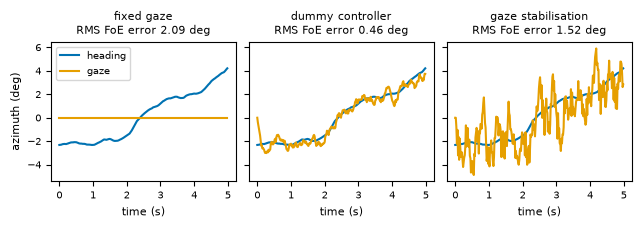

In [8]:
CYLINDER = dict(size=128, noise_std=0.01, n_steps=300)
DUMMY = dict(noise_std=1.0, lag=3, gain=0.15)
STABILISE = dict(gain=0.4)

tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), **CYLINDER)
models = {
    "fixed gaze": avb.FixedGazeModel(),
    "dummy controller": avb.DummyController(**DUMMY),
    "gaze stabilisation": avb.GazeStabilisationModel(**STABILISE),
}

def rollout(task, model, trial):
    """Play one closed-loop episode and return the time, the heading and the gaze."""
    obs = task.reset(trial)
    model.reset(trial.seed)
    t, heading, gaze, done = [], [], [], False
    while not done:
        t.append(obs.t)
        heading.append(obs.info["heading"])           # ground truth, for the figure only
        gaze.append(obs.gaze)
        obs, done, _ = task.step(model.act(obs))
    return np.array(t), np.array(heading), np.array(gaze)

trial = tunnel.generate_trial(3)
fig, axes = avb.new_figure(16, 5.5, 1, 3, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    t, heading, gaze = rollout(tunnel, model, trial)
    ax.plot(t, heading, color=BLUE, label="heading")
    ax.plot(t, gaze, color=ORANGE, label="gaze")
    ax.set_title(f"{name}\nRMS FoE error {np.sqrt(np.mean((heading - gaze) ** 2)):.2f} deg")
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("azimuth (deg)")
axes[0].legend()
save(fig, "02_cylinder_trajectories")

### Benchmark AVB2: `cylinder`

The observer travels along the axis of a tunnel and **keeps its gaze on the axis**: the target is the FoE, which
diffuses slowly in the image, and the model rotates the gaze to bring it back to the centre. This benchmark is
**active**: the gaze shift returned by the model is applied to the camera. The heading does not follow the gaze
(`heading_lag=None`), so that the model has to find the FoE with its gaze, as the section on the lag below shows.

| Symbol | Name in the code | Value | Role |
|--------|------------------|-------|------|
| | `size` | 128 pixels | side of the image |
| | `visual_angle` | 45 deg | visual angle of the width of the image |
| $R$ | `radius` | 1 m | radius of the tunnel |
| | `period` | 10 m | period of the texture along the tunnel |
| $v$ | `speed` | 6 m/s | speed of the camera (the expansion of a tunnel is weak near its axis) |
| $\Delta t$ | `dt` | 1/60 s | duration of a step |
| | `n_steps` | 300 (5 s) | steps of a trial |
| | `depth_exponent` | 2 | attenuation of the luminance with the distance (a headlight) |
| | `noise_std` | 0.01 | noise of the images (luminance) |
| $\tau$, $\sigma_\mathrm{OU}$ | `perturbation.tau`, `perturbation.sigma_ou` | 1 s, 2 deg | slow diffusion of the FoE |
| | `heading_lag` | `None` | the heading does not follow the gaze |

**Dataset:** 24 trials, seed 42. **Reference models:** `FixedGazeModel` and `GazeStabilisationModel` (gain $\kappa = 0.4$);
`DummyController` is a test double of the closed loop and not a model of the benchmark.
**Metric:** RMS error of the FoE (deg), $e = h - g$. The cell below prints the values that the task actually uses.


In [9]:
for name in ("size", "visual_angle", "radius", "period", "speed", "dt", "n_steps", "depth_exponent", "noise_std",
             "heading_lag"):
    print(f"{name:17s} {getattr(tunnel, name)}")
print(f"{'perturbation':17s} {tunnel.perturbation}")
print(f"{'seed':17s} {SEED}")

size              (128, 128)
visual_angle      45.0
radius            1.0
period            10.0
speed             6.0
dt                0.016666666666666666
n_steps           300
depth_exponent    2.0
noise_std         0.01
heading_lag       None
perturbation      Perturbation(dt=0.016666666666666666, tau=1.0, sigma_ou=2.0, mean=0.0, hazard_rate=0.0, sigma_jump=0.0, limit=None, seed=None, jump_tau=None)
seed              42


The same comparison on a dataset of trials (each with its own texture and its own diffusion of the heading):

fixed gaze           RMS error 2.11 deg, median over the trials 1.46 deg
dummy controller     RMS error 0.45 deg, median over the trials 0.34 deg
gaze stabilisation   RMS error 1.73 deg, median over the trials 1.39 deg


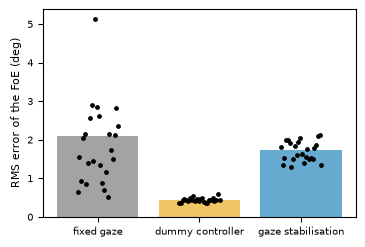

In [10]:
N_CYLINDER = avb.scaled(24, 4)
bench = avb.ActiveBenchmark(tunnel)
cylinder_trials = bench.generate_dataset(N_CYLINDER, seed=SEED)
cylinder = cached("02_cylinder", dict(cylinder=CYLINDER, dummy=DUMMY, stabilise=STABILISE, n_trials=N_CYLINDER, seed=SEED),
                  lambda: bench.evaluate(cylinder_trials, models, n_jobs=N_JOBS))

fig, ax = avb.new_figure(9, 6)
for k, (name, res) in enumerate(cylinder.items()):
    per_trial = [np.sqrt(r.mean_square_error) for r in res.trial_results]
    ax.bar(k, res.rms_error, color=[GREY, ORANGE, BLUE][k], alpha=0.6)
    ax.scatter(np.full(len(per_trial), k) + np.linspace(-0.2, 0.2, len(per_trial)), per_trial, s=6, color="k", zorder=3)
ax.set_xticks(range(len(cylinder)), cylinder.keys())
ax.set_ylabel("RMS error of the FoE (deg)")
save(fig, "02_cylinder_error")
for name, res in cylinder.items():
    print(f"{name:20s} RMS error {res.rms_error:.2f} deg, median over the trials {res.median_error:.2f} deg")

### The observer moves where it looks

In the active mode the observer can advance in the direction of its gaze. With `heading_lag` the heading is
pulled towards the gaze with a time constant (in seconds): `d heading = (gaze - heading) dt / lag`, in addition to
the exogenous diffusion. The shorter the lag, the more the heading follows the gaze **by itself** and the
more the perturbation is absorbed, which makes the control trivial: even a fixed gaze keeps the FoE near the
centre. This is why the benchmark leaves it off by default (`heading_lag=None`): the model has to find the
FoE with its gaze.

In [11]:
LAGS = [None, 2.0, 0.5, 0.2]
N_LAG = avb.scaled(8, 3)

def lag_sweep():
    out = {}
    for lag in LAGS:
        task = avb.CylinderTask(avb.MotionCloudStimulus(), heading_lag=lag, **CYLINDER)
        bench = avb.ActiveBenchmark(task)
        out[lag] = bench.evaluate(bench.generate_dataset(N_LAG, seed=SEED), {k: models[k] for k in ("fixed gaze", "gaze stabilisation")},
                                  n_jobs=N_JOBS)
    return out

by_lag = cached("02_lag", dict(lags=LAGS, cylinder=CYLINDER, stabilise=STABILISE, n_trials=N_LAG, seed=SEED), lag_sweep)
rows = ["| `heading_lag` | fixed gaze: RMS error (deg) | gaze stabilisation: RMS error (deg) |", "|---|---|---|"]
for lag, res in by_lag.items():
    rows.append(f"| {lag} | {res['fixed gaze'].rms_error:.2f} | {res['gaze stabilisation'].rms_error:.2f} |")
Markdown("\n".join(rows))

| `heading_lag` | fixed gaze: RMS error (deg) | gaze stabilisation: RMS error (deg) |
|---|---|---|
| None | 1.65 | 1.70 |
| 2.0 | 1.18 | 1.50 |
| 0.5 | 0.69 | 1.24 |
| 0.2 | 0.39 | 2.31 |

## Checks

**1. The target diffuses as predicted.** The signal of the perturbation has the stationary amplitude
$\sigma_\mathrm{OU}$ and the autocorrelation $(1 + |\Delta t|/\tau)\,e^{-|\Delta t|/\tau}$ of the Langevin
diffusion. It is smooth: it does not jitter from frame to frame.

stationary standard deviation: 2.009 deg (theory 2.0); largest step between frames: 0.154 deg


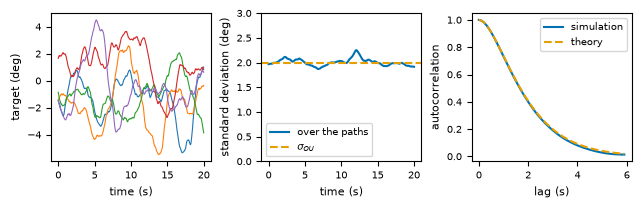

In [12]:
TAU, SIGMA, DT = 1.0, 2.0, 1 / 60
diffusion = avb.Perturbation(dt=DT, tau=TAU, sigma_ou=SIGMA)
n_steps = 20 * 60
paths = np.array([diffusion.sample(n_steps, seed=s) for s in range(avb.scaled(400, 40))])
time = np.arange(n_steps + 1) * DT
lags = np.arange(0, 6 * 60, 6)
autocorrelation = [np.mean(paths[:, : n_steps + 1 - k] * paths[:, k:]) / np.mean(paths * paths) for k in lags]

fig, axes = avb.new_figure(16, 5, 1, 3)
axes[0].plot(time, paths[:5].T, lw=0.8)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("target (deg)")
axes[1].plot(time, paths.std(axis=0), color=BLUE, label="over the paths")
axes[1].axhline(SIGMA, color=ORANGE, ls="--", label=r"$\sigma_{OU}$")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("standard deviation (deg)")
axes[1].set_ylim(0, 3)
axes[1].legend()
axes[2].plot(lags * DT, autocorrelation, color=BLUE, label="simulation")
axes[2].plot(lags * DT, (1 + lags * DT / TAU) * np.exp(-lags * DT / TAU), color=ORANGE, ls="--", label="theory")
axes[2].set_xlabel("lag (s)")
axes[2].set_ylabel("autocorrelation")
axes[2].legend()
save(fig, "02_checks_diffusion")
print(f"stationary standard deviation: {paths.std():.3f} deg (theory {SIGMA}); largest step between frames: "
      f"{np.abs(np.diff(paths, axis=1)).max():.3f} deg")

**2. The closed loop behaves as predicted with the test double.** With a perfect and immediate estimate
(no noise, no delay) the error stays small, and it increases with the noise and the delay of the
estimate, which are the two things the controller has to cope with. A proportional correction of an
estimate that is `lag` steps late is stable only for a gain below $2\sin\frac{\pi}{4\,\mathrm{lag}+2}$, that is
0.45 for 3 steps and 0.15 for 10 steps; the gain of 0.1 used here is stable for the three delays.

[]

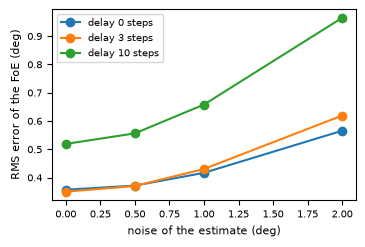

In [13]:
NOISES, DELAYS = [0.0, 0.5, 1.0, 2.0], [0, 3, 10]
N_DUMMY = avb.scaled(8, 3)

def dummy_sweep():
    task = avb.CylinderTask(avb.MotionCloudStimulus(), size=32, n_steps=300)
    bench = avb.ActiveBenchmark(task)
    trials = bench.generate_dataset(N_DUMMY, seed=SEED)
    return np.array([[bench.run(avb.DummyController(noise_std=n, lag=d, gain=0.1), trials, n_jobs=1).rms_error
                      for n in NOISES] for d in DELAYS])

errors = cached("02_dummy_sweep", dict(noises=NOISES, delays=DELAYS, n_trials=N_DUMMY, seed=SEED), dummy_sweep)

fig, ax = avb.new_figure(9, 6)
for row, delay in zip(errors, DELAYS):
    ax.plot(NOISES, row, "o-", label=f"delay {delay} steps")
ax.set_xlabel("noise of the estimate (deg)")
ax.set_ylabel("RMS error of the FoE (deg)")
ax.legend()
save(fig, "02_checks_dummy")

**3. $d'$ has the expected value.** For 84 hits out of 100 target-present trials and 16 false alarms out of 100
target-absent trials, the rates are symmetrical around 0.5 and $d'$ is twice the $z$-score of 0.84, that is
about $2 \times 0.994 = 1.99$ (the loglinear correction moves it slightly).

In [14]:
def synthetic(hits, false_alarms, n=100):
    results = []
    for present, count in ((True, hits), (False, false_alarms)):
        for k in range(n):
            decision = k < count
            results.append(avb.TrialResult(trial=avb.Trial(target_present=present), estimates=np.zeros(1), truth=np.zeros(1),
                                           errors=np.zeros(1), decision=decision, correct=decision == present, elapsed_s=0.0))
    return avb.BenchmarkResult(results)

for hits, false_alarms in ((84, 16), (50, 50), (100, 0)):
    r = synthetic(hits, false_alarms)
    print(f"H = {r.hit_rate():.2f}, F = {r.false_alarm_rate():.2f}: A = {r.accuracy:.2f}, d' = {r.d_prime():.3f}")

H = 0.84, F = 0.16: A = 0.84, d' = 1.961
H = 0.50, F = 0.50: A = 0.50, d' = 0.000
H = 1.00, F = 0.00: A = 1.00, d' = 5.159
